# TUTORIAL <span style="color:orange;">***MASAÏ***</span><img width='64' style="float:right;margin:0 10px 0 20px;" src="images/masai.png" />

Back to the main [Index](Index.ipynb)

## Part 8 bis . 2D EXSY processing in TPPI mode

#### Various imports and graphics settings

In [1]:
from __future__ import print_function

#### Loading the <span style="color:orange;">***MASAÏ***</span> library

In [2]:
from masai.api import *

MASAI api loaded: version 0.2.4.11

The current directory is </Users/christian/Dropbox/D.PROGRAMMES/masai/doc/tutorial>
MASAI root directory is </Users/christian/Dropbox/D.PROGRAMMES/masai>


#### Set up the general location of data

In [3]:
import os
# You should set the MASAI environnement variable before running these exemples')
# or change the two following paths according to your installation
DATADIR = os.path.join(MASAI,'doc/tutorial/exemples')
FIGDIR = os.path.join(MASAI,'doc/tutorial/figures')

## Load and plot a 2D fid

In [4]:
user = 'user'
name = 'EXSY_TPPI'
expno = 45
path = os.path.join(DATADIR, user,'nmr',name, str(expno))
source = Bruker(path) 
source

***Bruker Source***
- path: /Users/christian/Dropbox/D.PROGRAMMES/masai/doc/tutorial/exemples/user/nmr/EXSY_TPPI/45
- datatype: 2D NMR SER
- pulse program: noesyph
- Encoding: TPPI
- TD1: 256, TD2: 4096
- F1 limits: 0.00 to 7.191 ms
- F2 limits: 0.00 to 246.519 ms

In [5]:
#pathpp = os.path.join(source.path,'pulseprogram')
#%load $pathpp

<IPython.core.display.Javascript object>


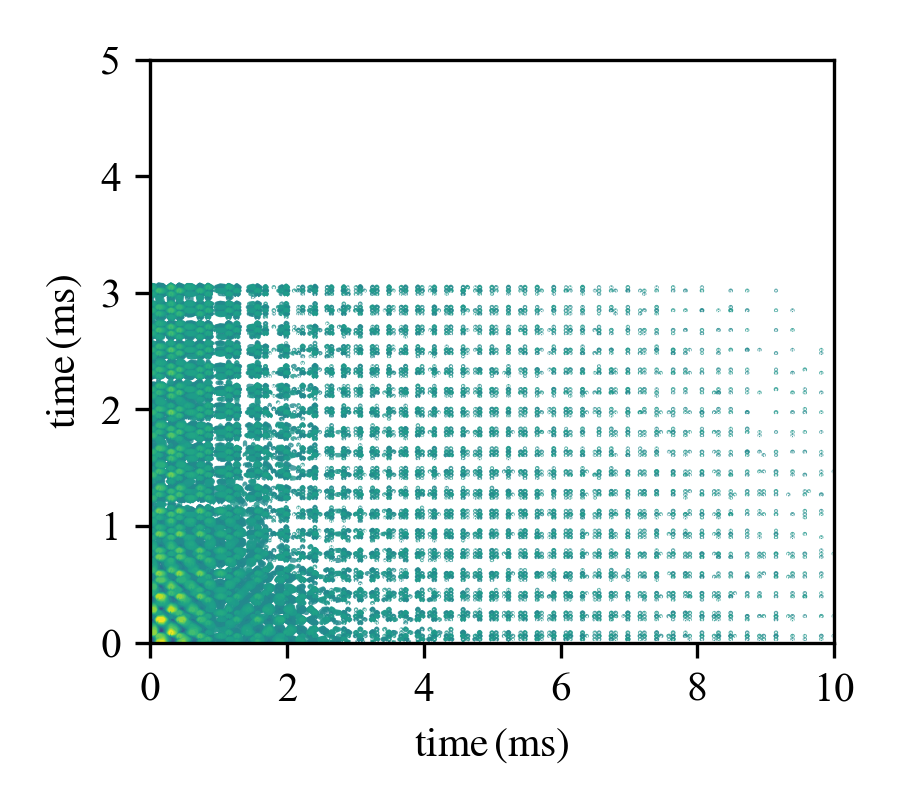

D8 is the mixing time: 100.00 ms


In [6]:
p_2 = Plot2d(source, figsize=(3,2.7), xlim=(0, 10), ylim=(0, 5))  
d8 = float(source.par.D[8])*1000.
print("D8 is the mixing time: %.2f ms"%d8)

## Process SER data

#### Process the first dimension

Exponential apodization lb:1.00
Zero-filling to si:8192
Fourier transform with si:8192
clipping along axis -1
Phasing phc0:170.60, phc1:-2.00


<IPython.core.display.Javascript object>


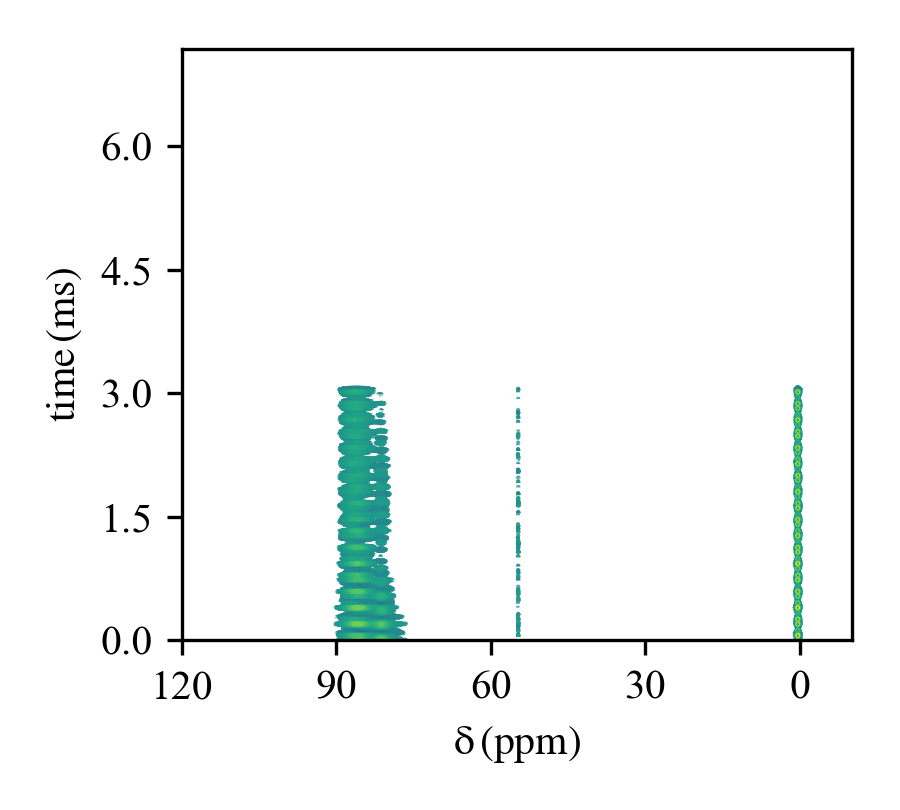

taking horizontal (axis=1) section by index at index 0


<IPython.core.display.Javascript object>


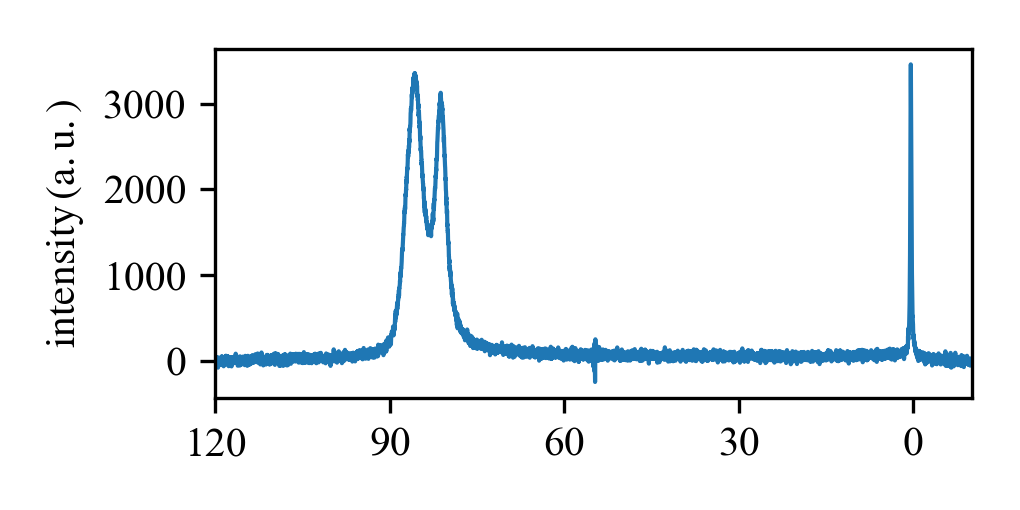

In [50]:
source = Bruker(path) 
Process(source, transform = 'em 1') # --k_shifted 1 0')

Process(source, transform = 'zf 1') 
Process(source, transform = 'ft')

Process(source, transform = 'cl -10 120')

#Process(source, transform = 'pk 0 0 --auto')# --fit_phc1')
Process(source, transform = 'pk 90 -2 --pivot 0.6')

p_2 = Plot2d(source, figsize=(3,2.7))

row = source.get_row(0, byindex=True)
p_1 = Plot1d(row, reverse=True)

#### Process the second dimension

Phasing phc0:170.60, phc1:-2.00
Exponential apodization lb:20.00
Zero-filling to si:256
Data transform according to encoding TPPI
Fourier transform with si:256
Phasing phc0:-58.00, phc1:-180.00


<IPython.core.display.Javascript object>


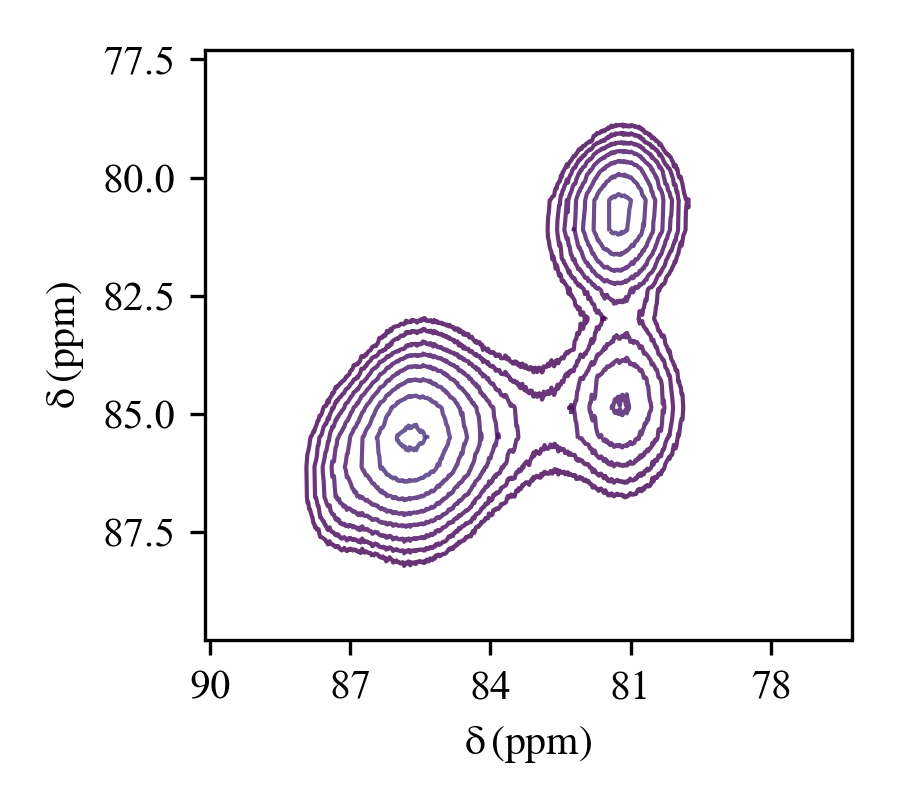

taking vertical (axis=0) section by position from 80.39 to 81.38


<IPython.core.display.Javascript object>


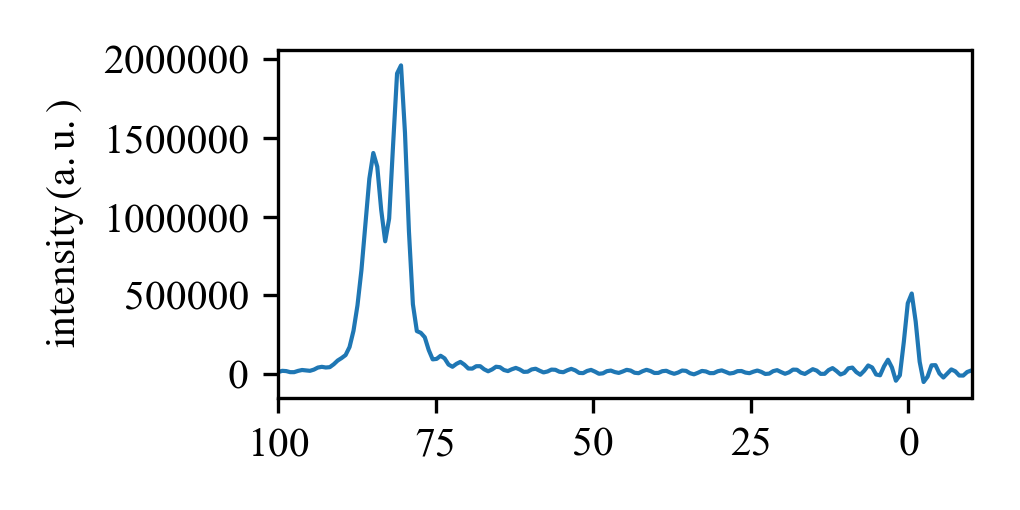

In [55]:
backup = source.copy(deepcopy=True)   # preserve the original dataset
Process(backup, axis=0, transform='em 20')
Process(backup, axis=0, transform='zf 0') 
Process(backup, axis=0, transform='ft')
#manual phasinf first needed
Process(backup, axis=0, transform='pk -150 0 --select cols --pivot 0.6') 

p_2 = Plot2d(backup, figsize=(3,2.7), xlim=(100,-10), ylim=(100,-10),
            start=0)

row = backup.get_col(80.88,width=1.)
p_1 = Plot1d(row, reverse=True, xlim=(100,-10))

<IPython.core.display.Javascript object>


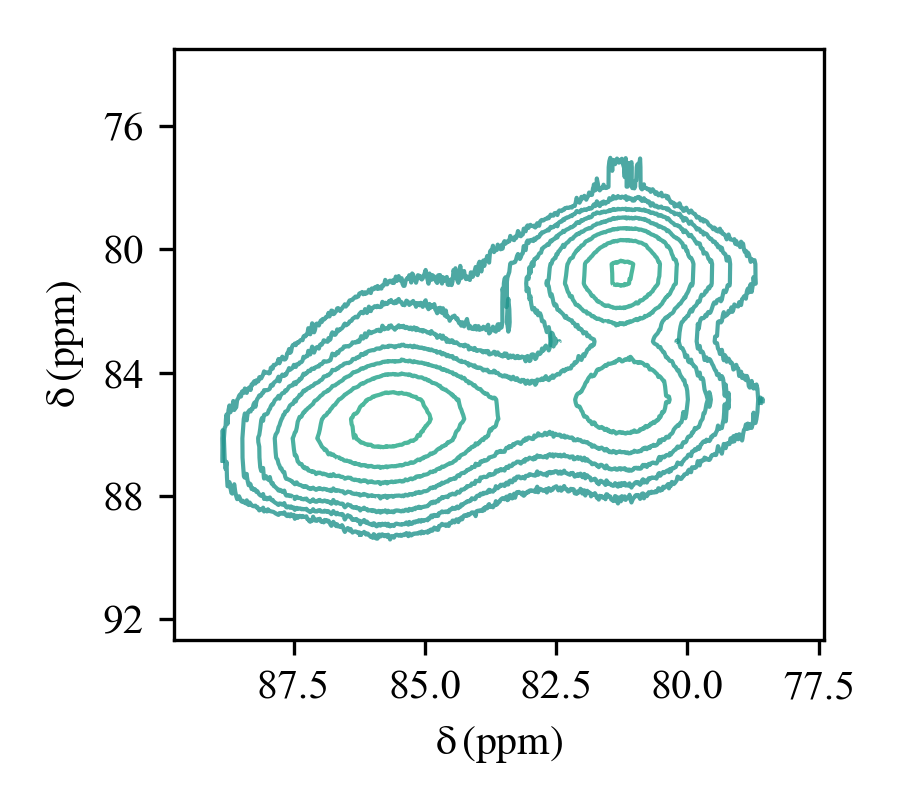

In [56]:
p_2 = Plot2d(backup, figsize=(3,2.7), xlim=(100,-10), ylim=(100,-10),
            start=-1, exponent=1.4, nc=50)

Phasing phc0:-58.00, phc1:-180.00
baseline correction mode:poly


<IPython.core.display.Javascript object>


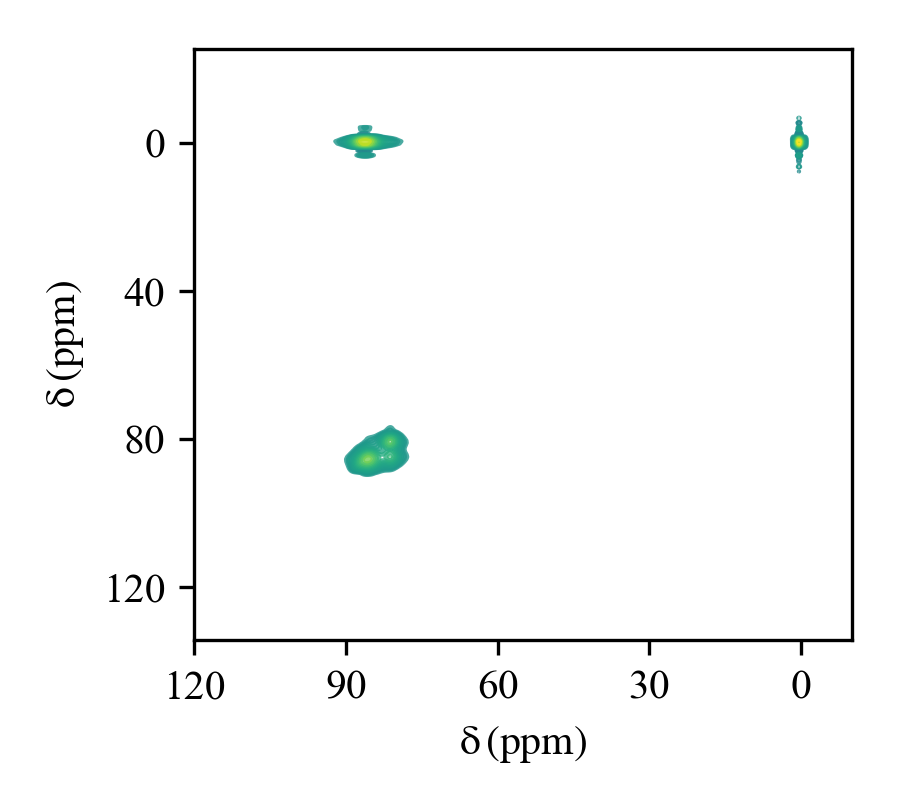

taking vertical (axis=0) section by position from 80.39 to 81.38


<IPython.core.display.Javascript object>


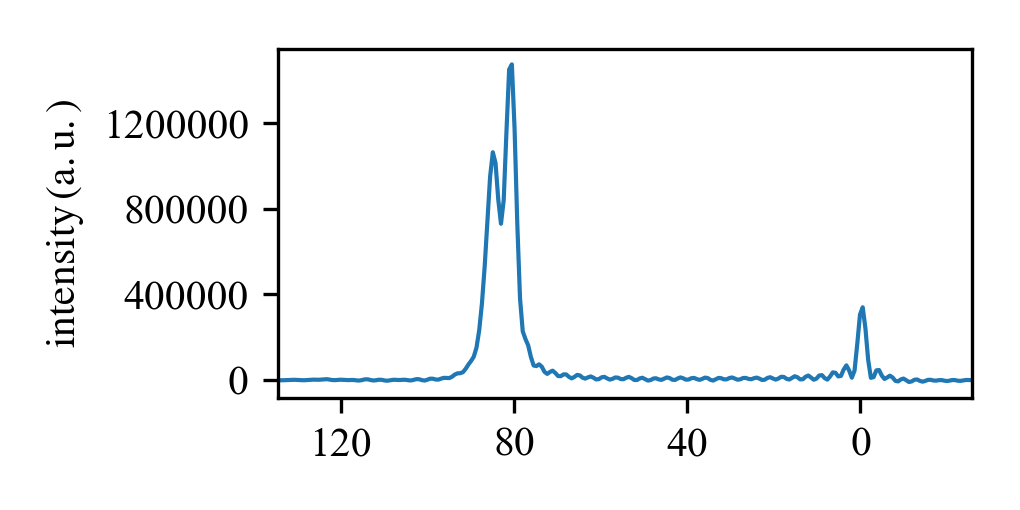

In [9]:
backup1 = backup.copy(deepcopy=True)
Process(backup1, axis=0, transform = "ab --mode poly")

p_2 = Plot2d(backup1, figsize=(3,2.7))

row = backup1.get_col(80.88,width=1.)
p_1 = Plot1d(row, reverse=True)

Back to the main [Index](Index.ipynb)

In [12]:
Plot2d()
